# Topology module

In [21]:
!pip install ripser
!pip install persim
!pip install gudhi

In [22]:
from sklearn.datasets import make_circles
from sklearn.utils import shuffle
import matplotlib.pyplot as plt

## Usage sample:

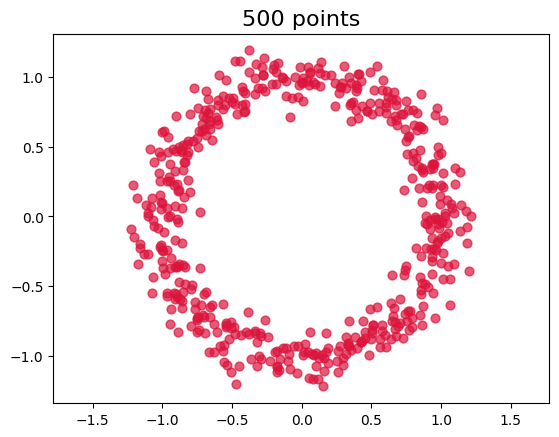

In [23]:
from Visualization import Visualization as vis

X, Y = make_circles(n_samples=1000, noise=0.1, factor=0.99, random_state=0, shuffle=False)
data = X[Y == 0]

vis.plot_data_cloud(data)

## Step 1. Estimation of Betti's Dynamics

In [24]:
from Betti import BettiNumbersCalculator

betti_calculator = BettiNumbersCalculator()
dynamics = betti_calculator.compute_betti_numbers_dynamics(data)

dynamics.T[-5:]

array([[0.17820515, 4.        ],
       [0.18898547, 3.        ],
       [0.19976443, 2.        ],
       [0.20513526, 1.        ],
       [1.37350047, 0.        ]])

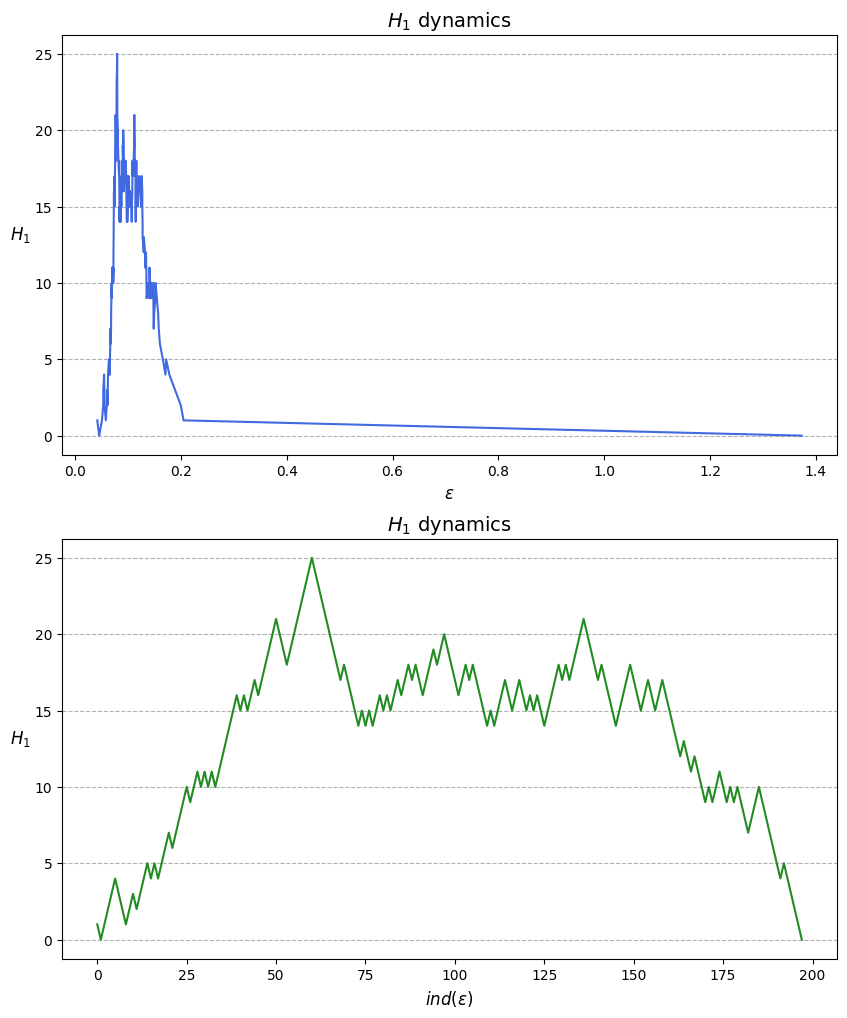

In [25]:
betti_calculator.plot_betti_numbers_dynamics()

## Step 2. Computation of Homologies

In [26]:
epsilon = 0.21

In [27]:
from Homology import MatrixHomologyCalculator

model = MatrixHomologyCalculator()
homology_boundaries = model.compute_homologies(data, epsilon)

Boundary matrix reduction: 100%|██████████| 5927/5927 [00:39<00:00, 149.44it/s]

Execution time: 0.0 m. 39.784 sec.


In [28]:
from Homology import ListHomologyCalculator

model = ListHomologyCalculator()
homology_boundaries = model.compute_homologies(data, epsilon)

Boundary matrix reduction: 100%|██████████| 5927/5927 [00:00<00:00, 29017.43it/s]

Execution time: 0.0 m. 0.307 sec.


In [29]:
from Homology import ColistHomologyCalculator

model = ColistHomologyCalculator()
homology_boundaries = model.compute_homologies(data, epsilon)

Boundary matrix reduction: 100%|██████████| 500/500 [00:00<00:00, 2048.39it/s]


Execution time: 0.0 m. 0.513 sec.


In [30]:
model.get_homologies_sizes()[-5:].T

array([[18, 19, 43, 44, 45],
       [10,  3, 25, 64,  9]])

## Step 3. Visualization of topological patterns

In [31]:
from Visualization import Visualization as vis

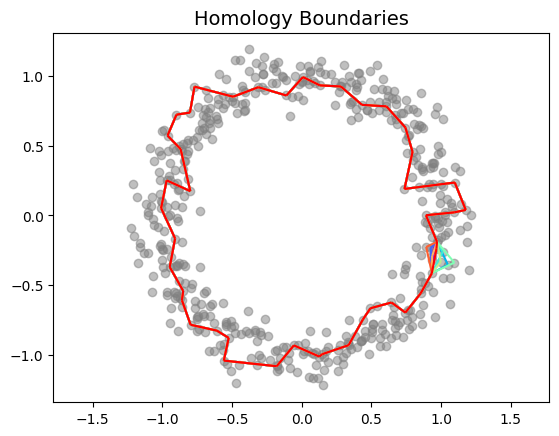

In [32]:
biggest_homologies = [
    h for h in homology_boundaries.values() if len(h.boundaries) == 45
]

mutual_homology = biggest_homologies[0]
for h in biggest_homologies:
    mutual_homology += h

vis.plot_homologies(data, biggest_homologies, palette='rainbow')

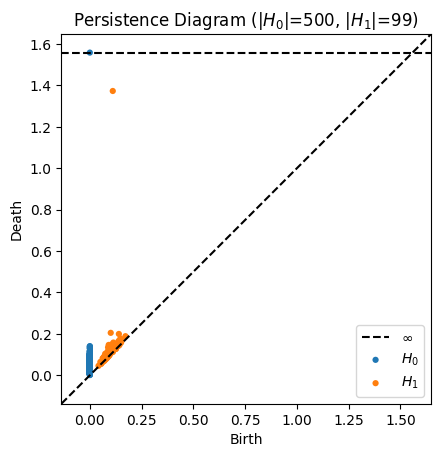

In [33]:
vis.plot_persistence_diagram(data)

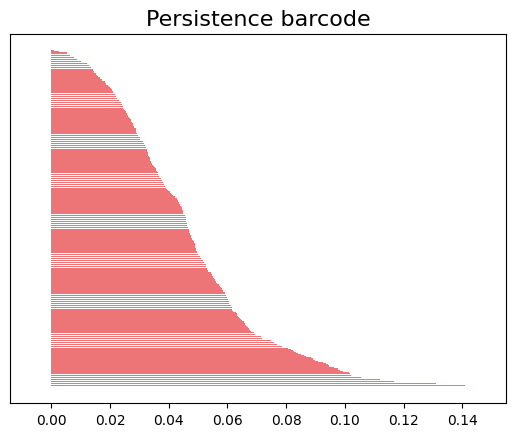

In [34]:
vis.plot_persistence_entropy(data)

## Testing the correctness of the module

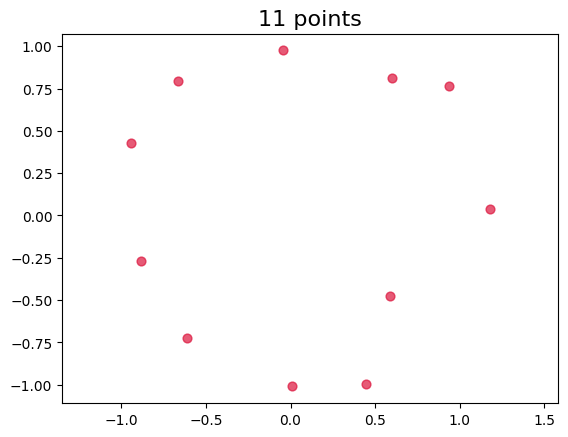

In [35]:
X, Y = make_circles(n_samples=22, noise=0.1, factor=0.99, random_state=0, shuffle=False)
data_simple = shuffle(X[Y == 0], random_state=42)

epsilon_simple = 0.79

vis.plot_data_cloud(data_simple)

In [36]:
import unittest

class TestHomologyCalculator(unittest.TestCase):

    def test_on_simple_data(self, data, epsilon):
        '''
        Тест, проверяющий корректность вычисления гомологий на простом
        наборе данных, состоящем из 11 точек
        '''
        print('\nTesting simple case...')

        model = ColistHomologyCalculator()
        homology_boundaries = model.compute_homologies(data, epsilon)

        self.assertEqual(model.get_homologies_sizes().T[-1, -1], 1)

    def test_on_complex_data(self, data, epsilon):
        '''
        Тест, проверяющий корректность вычисления гомологий на объёмном
        наборе данных, состоящем из 500 точек
        '''
        print('\nTesting complex case...')

        model = ColistHomologyCalculator()
        homology_boundaries = model.compute_homologies(data, epsilon)

        self.assertEqual(model.get_homologies_sizes().T[-1, -1], 9)

tester = TestHomologyCalculator()
tester.test_on_simple_data(data_simple, epsilon_simple)
tester.test_on_complex_data(data, epsilon=epsilon)


Testing simple case...


Boundary matrix reduction: 100%|██████████| 11/11 [00:00<00:00, 17050.02it/s]


Execution time: 0.0 m. 0.012 sec.

Testing complex case...


Boundary matrix reduction: 100%|██████████| 500/500 [00:00<00:00, 1939.95it/s]


Execution time: 0.0 m. 0.519 sec.
